# Chapitre 12 - Cours 2 : SVM à noyaux, perte charnière, chemin de régularisation, régression

Ce notebook couvre la section 12.3 du livre :

1. l'**astuce du noyau** : le dual ne dépend que de produits scalaires (éq. (12.19)–(12.24)) ;
2. les SVM non linéaires sur la simulation « mixture » (figure 12.3) ;
3. le SVM vu comme une méthode **perte + pénalité** : la **perte charnière** comparée aux
   autres pertes (figure 12.4, tableau 12.1) ;
4. l'interprétation par les espaces de fonctions engendrés par un noyau, et la version
   « régression logistique à noyau » (figure 12.5) ;
5. le choix de $C$ et du paramètre du noyau (figure 12.6), le **chemin de régularisation**
   (figure 12.7) ;
6. les SVM pour la **régression** (figure 12.8) et la régression ridge à noyau
   (éq. (12.45)–(12.49)).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
from esl import datasets
from esl.ch12_svm import (SVMClassifier, SVMRegressor, polynomial_kernel, rbf_kernel,
                          poly2_features, hinge_loss, binomial_deviance, squared_error_loss,
                          huberized_hinge, eps_insensitive, huber_loss, kernel_ridge,
                          simulate_mixture, mixture_bayes_prob, plot_mixture_boundary)
set_style()

## 1. Agrandir l'espace des variables… sans le calculer

Pour obtenir des frontières non linéaires, on peut remplacer $x$ par un vecteur de
**fonctions de base** $h(x) = (h_1(x), \dots, h_M(x))$ (polynômes, splines… voir
chapitre 5) et appliquer le classifieur du cours 1 aux $h(x_i)$. Le dual (12.13) devient

$$L_D = \sum_i \alpha_i - \tfrac12\sum_i\sum_{i'}\alpha_i\alpha_{i'}y_iy_{i'}\,\langle h(x_i), h(x_{i'})\rangle \qquad (12.19)$$

et, grâce à $\beta = \sum_i \alpha_i y_i h(x_i)$, la fonction de décision s'écrit

$$f(x) = h(x)^T\beta + \beta_0 = \sum_i \alpha_i y_i\,\langle h(x), h(x_i)\rangle + \beta_0 \qquad (12.20).$$

**Observation clé.** Les deux formules ne font intervenir $h$ qu'à travers des produits
scalaires. Il suffit donc de connaître la fonction

$$K(x, x') = \langle h(x), h(x')\rangle \qquad (12.21),$$

appelée **noyau** : on n'a jamais besoin de calculer $h$ explicitement, même si $M$ est très
grand (voire infini).

**Quelles fonctions $K$ conviennent ?** $K$ doit être symétrique et **semi-définie
positive** : pour tous points $x_1,\dots,x_N$, la matrice de Gram $\mathbf{K} = [K(x_i, x_{i'})]$
vérifie $c^T\mathbf{K}c \ge 0$ pour tout $c\in\mathbb{R}^N$ (ses valeurs propres sont
positives). C'est évidemment nécessaire : $c^T\mathbf{K}c = \|\sum_i c_i h(x_i)\|^2$.

Trois noyaux classiques (éq. (12.22)) :

* polynomial de degré $d$ : $K(x,x') = (1 + \langle x, x'\rangle)^d$ ;
* radial (gaussien) : $K(x,x') = \exp(-\gamma\|x-x'\|^2)$ ;
* « réseau de neurones » : $K(x,x') = \tanh(\kappa_1\langle x,x'\rangle + \kappa_2)$.

**Exemple (12.23).** Pour $p = 2$ et $d = 2$, en développant le carré :

$$(1 + x_1x_1' + x_2x_2')^2 = 1 + 2x_1x_1' + 2x_2x_2' + (x_1x_1')^2 + (x_2x_2')^2 + 2x_1x_1'x_2x_2',$$

qui est bien $\langle h(x), h(x')\rangle$ avec
$h(x) = (1, \sqrt2x_1, \sqrt2x_2, x_1^2, x_2^2, \sqrt2x_1x_2)$, donc $M = 6$.

In [2]:
rng = np.random.RandomState(0)
A, B = rng.randn(5, 2), rng.randn(4, 2)
lhs = polynomial_kernel(A, B, degree=2)
rhs = poly2_features(A) @ poly2_features(B).T
print("écart max entre (1+<x,x'>)^2 et <h(x),h(x')> :", np.abs(lhs - rhs).max())

écart max entre (1+<x,x'>)^2 et <h(x),h(x')> : 3.552713678800501e-15


Vérifions numériquement la positivité : plus petite valeur propre de la matrice de Gram sur
200 points, pour chaque noyau. Le noyau tanh **n'est pas** semi-défini positif en général.

In [3]:
Z = rng.randn(200, 2)
grams = {
    "polynomial d=4": polynomial_kernel(Z, Z, degree=4),
    "radial gamma=1": rbf_kernel(Z, Z, 1.0),
    "tanh(1<x,x'> + 1)": np.tanh(Z @ Z.T + 1.0),
}
for name, Kz in grams.items():
    print("%-20s : plus petite valeur propre = %+.3e" % (name, np.linalg.eigvalsh(Kz).min()))

polynomial d=4       : plus petite valeur propre = -9.181e-12
radial gamma=1       : plus petite valeur propre = -1.870e-15
tanh(1<x,x'> + 1)    : plus petite valeur propre = -2.234e+01


Une fois $\hat\alpha$ et $\hat\beta_0$ calculés, la fonction de décision est

$$\hat f(x) = \sum_{i=1}^N \hat\alpha_i y_i K(x, x_i) + \hat\beta_0 \qquad (12.24),$$

et seuls les vecteurs de support ($\hat\alpha_i > 0$) interviennent dans la somme.

## 2. SVM non linéaires sur la simulation « mixture » (figure 12.3)

In [4]:
mix = datasets.load_mixture_example()
X = mix["x"]
y = np.where(mix["y"] == 1, 1.0, -1.0)
rng = np.random.RandomState(0)
Xtest, ytest01 = simulate_mixture(5000, mix["means"], rng)
ytest = np.where(ytest01 == 1, 1, -1)
bayes_err = np.mean((mixture_bayes_prob(Xtest, mix["means"]) > 0.5) != ytest01)
print("erreur de Bayes : %.3f" % bayes_err)

erreur de Bayes : 0.210


In [5]:
models = {
    "polynôme de degré 4": SVMClassifier(C=1, kernel="poly", degree=4).fit(X, y),
    "noyau radial, gamma = 1": SVMClassifier(C=1, kernel="rbf", gamma=1).fit(X, y),
}
for name, s in models.items():
    print("%-24s : erreur app. %.3f, test %.3f, vecteurs de support %d%%"
          % (name, np.mean(s.predict(X) != y), np.mean(s.predict(Xtest) != ytest),
             100 * len(s.support_) / len(y)))

polynôme de degré 4      : erreur app. 0.180, test 0.241, vecteurs de support 55%
noyau radial, gamma = 1  : erreur app. 0.160, test 0.215, vecteurs de support 58%


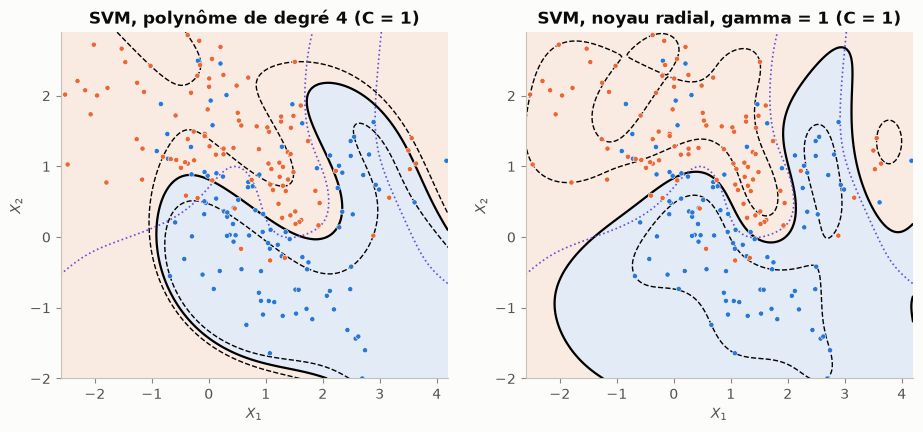

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, s) in zip(axes, models.items()):
    plot_mixture_boundary(ax, X, y, s.decision_function, mix["means"], margins=True,
                          title="SVM, %s (C = 1)" % name)
plt.show()

Comme dans le livre, le noyau radial donne une frontière très proche de celle de Bayes
(violet pointillé), ce qui n'est pas surprenant puisque les données sont des mélanges de
gaussiennes. Le livre rapporte 42 % et 45 % de points *non* supports ; on obtient des
proportions du même ordre.

**Rôle de $C$ dans l'espace agrandi.** Dans un espace de grande dimension, les classes
deviennent presque séparables. Un grand $C$ décourage tout écart $\xi_i > 0$ et produit une
frontière tortueuse (sur-apprentissage) ; un petit $C$ favorise un petit $\|\beta\|$ donc une
fonction $f$ plus lisse.

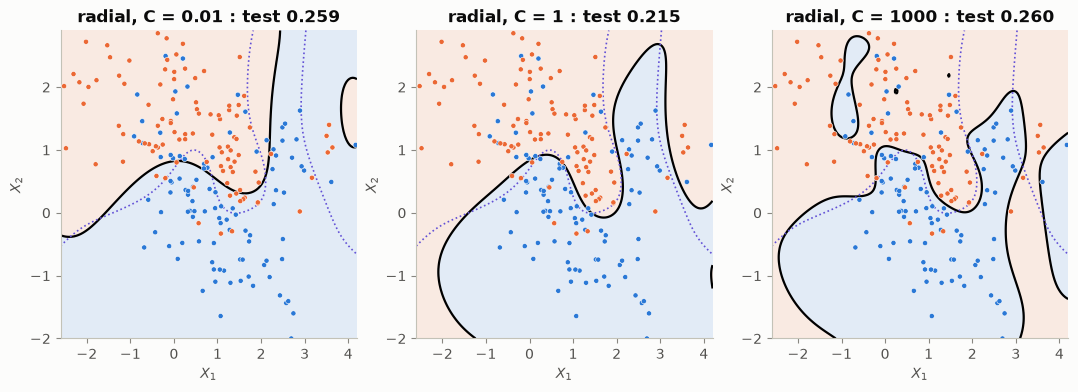

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, C in zip(axes, [0.01, 1, 1000]):
    s = SVMClassifier(C=C, kernel="rbf", gamma=1).fit(X, y)
    plot_mixture_boundary(ax, X, y, s.decision_function, mix["means"],
                          title="radial, C = %g : test %.3f" % (C, np.mean(s.predict(Xtest) != ytest)))
plt.show()

## 3. Le SVM comme méthode « perte + pénalité »

Avec $f(x) = h(x)^T\beta + \beta_0$, considérons

$$\min_{\beta_0, \beta}\ \sum_{i=1}^N\left[1 - y_if(x_i)\right]_+ + \frac\lambda2\|\beta\|^2 \qquad (12.25),$$

où $[u]_+ = \max(u, 0)$ désigne la partie positive. L'exercice 12.1 montre que, pour
$\lambda = 1/C$, la solution est celle de (12.8). L'idée : à $\beta$ fixé, le meilleur écart
admissible est $\xi_i = [1 - y_if(x_i)]_+$.

Vérification numérique : la valeur de (12.25) à la solution du SVM vaut $\lambda$ fois la
valeur optimale de (12.8).

In [8]:
s = SVMClassifier(C=1, kernel="rbf", gamma=1).fit(X, y)
lam = 1 / s.C
w = s.alpha_ * y
Kxx = s.K_(X, X)
crit_1225 = hinge_loss(y * s.decision_function(X)).sum() + lam / 2 * w @ Kxx @ w
print("critère (12.25) : %.6f   lambda x critère (12.8) : %.6f" % (crit_1225, lam * s.primal_objective()))

critère (12.25) : 86.933281   lambda x critère (12.8) : 86.933281


### 3.1 Comparaison des pertes (figure 12.4)

La **perte charnière** $L(y, f) = [1 - yf]_+$ ne dépend que de la **marge** $yf$. On la compare
à :

* la **déviance binomiale** (régression logistique) $\log(1 + e^{-yf})$ ;
* la **perte quadratique** $(y - f)^2 = (1 - yf)^2$ (car $y^2 = 1$) ;
* la **charnière quadratique « hubérisée »** : $[1-yf]_+^2$ si $yf \ge -1$, $-4yf$ sinon.

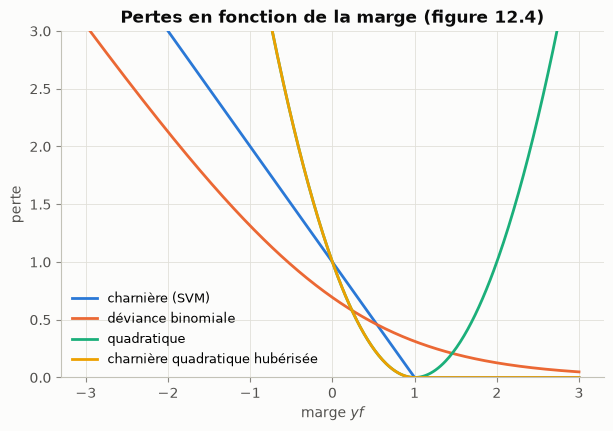

In [9]:
mgrid = np.linspace(-3, 3, 400)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(mgrid, hinge_loss(mgrid), color=COLORS[0], label="charnière (SVM)")
ax.plot(mgrid, binomial_deviance(mgrid), color=COLORS[1], label="déviance binomiale")
ax.plot(mgrid, squared_error_loss(mgrid), color=COLORS[2], label="quadratique")
ax.plot(mgrid, huberized_hinge(mgrid), color=COLORS[3], label="charnière quadratique hubérisée")
ax.set_ylim(0, 3); ax.set_xlabel("marge $yf$"); ax.set_ylabel("perte")
ax.set_title("Pertes en fonction de la marge (figure 12.4)")
ax.legend()
plt.show()

Lecture :

* la charnière et la déviance ont les mêmes asymptotes : perte nulle (ou presque) pour les
  points bien à l'intérieur de leur marge, et pente $-1$ pour les points mal classés et
  lointains (pénalité **linéaire**, donc robuste) ;
* la perte quadratique pénalise aussi les points **très bien classés** ($yf > 1$) et croît
  quadratiquement à gauche : elle est sensible aux points aberrants.

### 3.2 Ce que chaque perte estime (tableau 12.1)

Au niveau de la population, on cherche, pour chaque $x$, la valeur $f$ minimisant
$\mathbb{E}[L(Y, f) \mid X = x] = p\,L(+1, f) + (1-p)\,L(-1, f)$ avec $p = \Pr(Y = +1\mid x)$.

**Exemple : la perte charnière.** La fonction $\psi(f) = p[1-f]_+ + (1-p)[1+f]_+$ est
affine par morceaux. Sur $[-1, 1]$, $\psi(f) = p(1-f) + (1-p)(1+f) = 1 + (1-2p)f$ ; hors de
cet intervalle elle croît. Le minimum est donc en $f = 1$ si $p > 1/2$ et en $f = -1$ si
$p < 1/2$ : $f^\star = \mathrm{sign}(p - 1/2)$. La perte charnière estime **directement le
classifieur**, pas les probabilités.

**Les autres.** Pour la déviance, annuler la dérivée $-p\sigma(-f) + (1-p)\sigma(f)$ (où
$\sigma(u) = 1/(1+e^{-u})$) donne $f^\star = \log\frac{p}{1-p}$ ; pour la perte quadratique,
$f^\star = \mathbb{E}[Y\mid x] = 2p - 1$ ; il en est de même pour la version hubérisée.

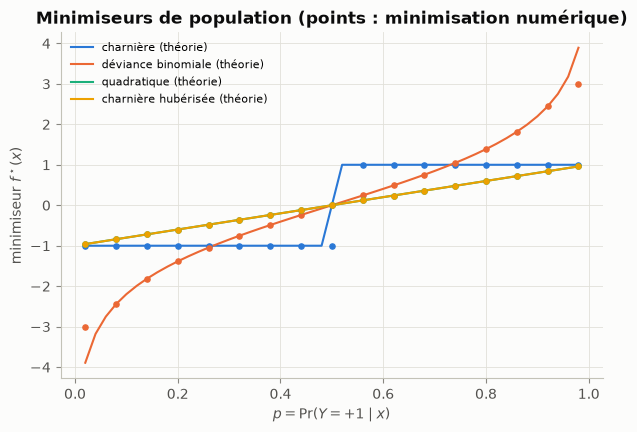

In [10]:
p_grid = np.linspace(0.02, 0.98, 49)
f_grid = np.linspace(-3, 3, 6001)
losses = {"charnière": hinge_loss, "déviance binomiale": binomial_deviance,
          "quadratique": squared_error_loss, "charnière hubérisée": huberized_hinge}
theory = {"charnière": np.sign(p_grid - 0.5), "déviance binomiale": np.log(p_grid / (1 - p_grid)),
          "quadratique": 2 * p_grid - 1, "charnière hubérisée": 2 * p_grid - 1}
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, (name, L) in enumerate(losses.items()):
    risk = p_grid[:, None] * L(f_grid)[None, :] + (1 - p_grid[:, None]) * L(-f_grid)[None, :]
    fstar = f_grid[risk.argmin(1)]
    ax.plot(p_grid, theory[name], color=COLORS[k], lw=1.5, label=name + " (théorie)")
    ax.scatter(p_grid[::3], fstar[::3], color=COLORS[k], s=14, zorder=3)
ax.set_xlabel(r"$p = \Pr(Y=+1 \mid x)$"); ax.set_ylabel(r"minimiseur $f^\star(x)$")
ax.set_title("Minimiseurs de population (points : minimisation numérique)")
ax.legend(fontsize=8)
plt.show()

> **À retenir.** Toutes ces pertes, sauf la perte quadratique, sont « maximisant la marge » :
> si les données sont séparables, la solution de (12.25) tend, quand $\lambda\to0$, vers
> l'hyperplan de marge maximale. Seule la charnière est nulle sur toute une demi-droite, ce
> qui produit des solutions **creuses** (beaucoup de $\hat\alpha_i = 0$).

## 4. Noyaux et estimation de fonctions

Si $K$ admet un développement $K(x,x') = \sum_m \delta_m\phi_m(x)\phi_m(x')$ (éq. (12.26)),
avec $h_m = \sqrt{\delta_m}\phi_m$, le problème (12.25) se réécrit avec une pénalité
$\frac{\lambda}{2}\sum_m\theta_m^2/\delta_m$ (éq. (12.27)) qui pénalise davantage les
fonctions $\phi_m$ de petite valeur propre $\delta_m$ (en général les plus « rugueuses »).
La théorie de la section 5.8 garantit alors une solution de dimension finie

$$f(x) = \beta_0 + \sum_{i=1}^N\alpha_iK(x, x_i) \qquad (12.28),$$

et le critère devient
$\min_{\beta_0,\alpha}\sum_i(1 - y_if(x_i))_+ + \frac\lambda2\alpha^T\mathbf K\alpha$ (12.29)
(exercice 12.2).

**Conséquence.** Rien n'impose la perte charnière : on peut utiliser n'importe quelle perte
convexe avec le même noyau. Avec la déviance binomiale, on obtient une **régression
logistique à noyau** qui estime le log-rapport des chances (12.31) et donc des probabilités
(12.32). Implémentons-la par la méthode de Newton sur
$J(\beta_0,\alpha) = \sum_i\log(1+e^{-y_if(x_i)}) + \frac\lambda2\alpha^T\mathbf K\alpha$.

Avec $\theta = (\beta_0, \alpha)$, $f = \tilde{\mathbf K}\theta$ où
$\tilde{\mathbf K} = [\mathbf 1\ \mathbf K]$. Le gradient et la hessienne sont

$$\nabla J = -\tilde{\mathbf K}^T(y \odot \sigma(-y\odot f)) + \lambda P\theta,\qquad
\nabla^2J = \tilde{\mathbf K}^T W\tilde{\mathbf K} + \lambda P,$$

avec $W = \mathrm{diag}(\sigma(f_i)(1-\sigma(f_i)))$ et $P = \mathrm{diag}(0, \mathbf K)$
(bloc). On itère $\theta \leftarrow \theta - (\nabla^2J)^{-1}\nabla J$.

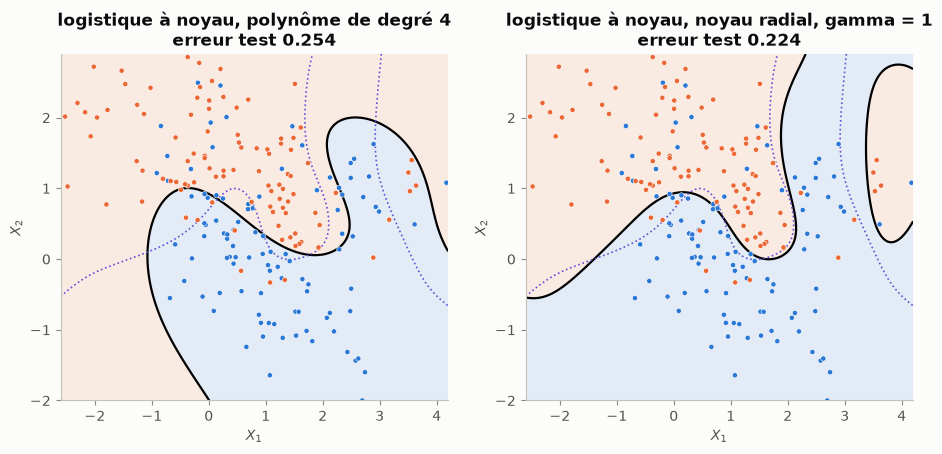

In [11]:
def kernel_logistic(K, y, lam, n_iter=50):
    """Régression logistique à noyau par Newton ; renvoie (beta0, alpha)."""
    N = len(y)
    Kt = np.column_stack([np.ones(N), K])
    P = np.zeros((N + 1, N + 1)); P[1:, 1:] = K
    theta = np.zeros(N + 1)
    for _ in range(n_iter):
        f = Kt @ theta
        sig = 1 / (1 + np.exp(-f))
        grad = -Kt.T @ (y / (1 + np.exp(y * f))) + lam * P @ theta
        Hs = Kt.T @ ((sig * (1 - sig))[:, None] * Kt) + lam * P + 1e-10 * np.eye(N + 1)
        theta -= np.linalg.lstsq(Hs, grad, rcond=None)[0]
    return theta[0], theta[1:]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, kfun) in zip(axes, [("polynôme de degré 4", lambda A, B: polynomial_kernel(A, B, degree=4)),
                                   ("noyau radial, gamma = 1", lambda A, B: rbf_kernel(A, B, 1.0))]):
    Kx = kfun(X, X)
    b0, al = kernel_logistic(Kx, y, lam=1.0)       # même lambda = 1/C = 1 que les SVM ci-dessus
    fun = lambda Z, b0=b0, al=al, kfun=kfun: kfun(Z, X) @ al + b0
    err = np.mean(np.sign(fun(Xtest)) != ytest)
    plot_mixture_boundary(ax, X, y, fun, mix["means"], title="logistique à noyau, %s\nerreur test %.3f" % (name, err))
plt.show()

Les frontières ressemblent à celles des SVM (figure 12.5 du livre). En revanche, aucun
$\alpha_i$ n'est nul : la déviance ne s'annule jamais, donc la solution n'est pas creuse.

## 5. Choix des paramètres et chemin de régularisation

### 5.1 Erreur test en fonction de $C$ et de $\gamma$ (figure 12.6)

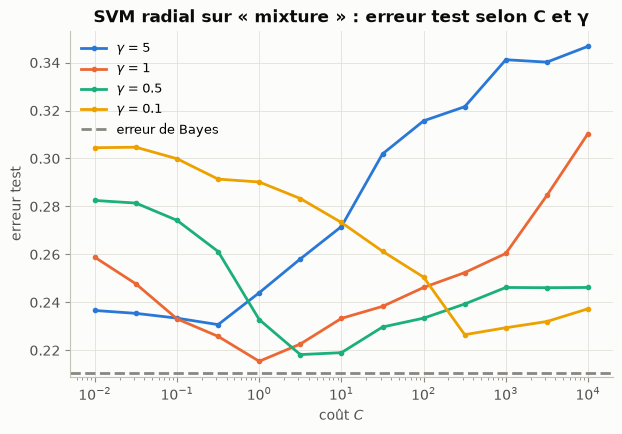

In [12]:
gammas = [5, 1, 0.5, 0.1]
Cs = np.logspace(-2, 4, 13)
errs = np.array([[np.mean(SVMClassifier(C=C, kernel="rbf", gamma=g).fit(X, y).predict(Xtest) != ytest)
                  for C in Cs] for g in gammas])
fig, ax = plt.subplots(figsize=(7, 4.5))
for k, g in enumerate(gammas):
    ax.semilogx(Cs, errs[k], marker="o", ms=3, color=COLORS[k], label=r"$\gamma$ = %g" % g)
ax.axhline(bayes_err, color=GRAY, ls="--", label="erreur de Bayes")
ax.set_xlabel("coût $C$"); ax.set_ylabel("erreur test")
ax.set_title("SVM radial sur « mixture » : erreur test selon C et γ")
ax.legend()
plt.show()